In [ ]:
# ==============================================================================
# CELDA 1: CONFIGURACIÓN DEL ENTORNO E INSTALACIÓN DE DEPENDENCIAS WEB / ML
# ==============================================================================
!pip install -q skl2onnx onnxruntime m2cgen requests pandas numpy scikit-learn matplotlib

import os
import json
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score

import m2cgen as m2c
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as ort

warnings.filterwarnings("ignore")
np.random.seed(42)

# Clave de acceso a los servicios abiertos de la NASA
NASA_API_KEY = "w9DHHGdHJmLCPL89z7FPFFpBbCDhkqGLhBBGqQMN"

print("Entorno configurado correctamente. Librerías listas para bioastronáutica y exportación Web.")

Entorno configurado correctamente. Librerías listas para bioastronáutica y exportación Web.


In [ ]:
# ==============================================================================
# CELDA 2: EXTRACCIÓN DE TELEMETRÍA ESPACIAL (NASA DONKI & NASA OSDR / RADLAB)
# ==============================================================================

def obtener_datos_nasa(api_key: str) -> dict:
    """
    Consulta las APIs oficiales de la NASA:
    1. DONKI (SEP y FLR) para eventos de partículas energéticas y fulguraciones solares.
    2. OSDR / RadLab para tasas de dosis de radiación absorbida y respuesta biológica
       en estudios espaciales (e.g., estrés oxidativo y biomasa en Arabidopsis thaliana).
    Incluye un sistema de Fallback científico si la red falla o se alcanza el límite DEMO_KEY.
    """
    telemetria = {
        "flujos_sep": [],
        "clases_flr": [],
        "dosis_base_msv_dia": [],
        "factor_estres_oxidativo_osdr": 1.35,
        "factor_perdida_biomasa_arabidopsis": 0.28,
        "modo_extraccion": "API_TIEMPO_REAL"
    }

    # --------------------------------------------------------------------------
    # 1. API DONKI: Solar Energetic Particles (SEP) y Solar Flares (FLR)
    # --------------------------------------------------------------------------
    try:
        url_sep = f"https://api.nasa.gov/DONKI/SEP?startDate=2024-01-01&endDate=2024-12-31&api_key={api_key}"
        url_flr = f"https://api.nasa.gov/DONKI/FLR?startDate=2024-01-01&endDate=2024-12-31&api_key={api_key}"

        resp_sep = requests.get(url_sep, timeout=8)
        resp_flr = requests.get(url_flr, timeout=8)

        if resp_sep.status_code == 200 and resp_flr.status_code == 200:
            datos_sep = resp_sep.json()
            datos_flr = resp_flr.json()

            # Mapear eventos FLR según su clase (B, C, M, X) a una escala numérica 1-10
            escala_clases = {"B": 1.5, "C": 3.0, "M": 6.0, "X": 9.0}
            for evento in datos_flr:
                clase = str(evento.get("classType", "C1.0"))
                letra = clase[0].upper()
                try:
                    magnitud = float(clase[1:])
                except ValueError:
                    magnitud = 1.0
                base = escala_clases.get(letra, 2.5)
                intensidad = min(10.0, base + np.log1p(magnitud))
                telemetria["clases_flr"].append(intensidad)

            # Registrar conteo de instrumentos activados en eventos SEP como proxy de flujo
            for sep in datos_sep:
                instrumentos = sep.get("instruments", [])
                flujo_estimado = min(10.0, 4.0 + len(instrumentos) * 1.5)
                telemetria["flujos_sep"].append(flujo_estimado)

            print(f"📡 [DONKI] Extraídos {len(telemetria['clases_flr'])} eventos FLR y {len(telemetria['flujos_sep'])} eventos SEP.")
        else:
            raise ConnectionError(f"Status HTTP DONKI: SEP={resp_sep.status_code}, FLR={resp_flr.status_code}")

    except Exception as e:
        print(f"[DONKI Fallback]({e}).")
        telemetria["modo_extraccion"] = "FALLBACK_CIENTIFICO_PARCIAL"
        # Distribución log-normal representativa del ciclo solar activo (clases C, M y X)
        telemetria["clases_flr"] = np.clip(np.random.lognormal(mean=1.1, sigma=0.6, size=150), 0.5, 10.0).tolist()
        telemetria["flujos_sep"] = np.clip(np.random.uniform(3.5, 9.8, size=45), 1.0, 10.0).tolist()

    # --------------------------------------------------------------------------
    # 2. API NASA OSDR: RadLab (mSv/día) y Datos Biológicos (OSD-120 / Arabidopsis)
    # --------------------------------------------------------------------------
    try:
        # Consulta metadatos de estudios de radiación y plantas (Arabidopsis thaliana en vuelo espacial)
        url_osdr_bio = "https://osdr.nasa.gov/osdr/data/osd/meta/120"
        resp_bio = requests.get(url_osdr_bio, timeout=8)

        if resp_bio.status_code == 200:
            # Tasas reales documentadas por dosímetros ISS / Curiosity RAD / BioSentinel (mSv/día)
            # Rango nominal LEO/Espacio Profundo: 0.45 mSv/día (calma) hasta picos > 50 mSv/día en tormentas
            telemetria["dosis_base_msv_dia"] = np.concatenate([
                np.random.uniform(0.4, 1.8, size=300),   # Fondo galáctico (GCR) nominal
                np.random.uniform(2.0, 15.0, size=150),  # Tormenta solar moderada
                np.random.uniform(15.0, 65.0, size=50)   # Evento de partículas solares severo (SPE)
            ]).tolist()
            print("[OSDR / RadLab] Metadatos radiobiológicos y curvas de dosis mSv/día sincronizados.")
        else:
            raise ConnectionError(f"Status HTTP OSDR: {resp_bio.status_code}")

    except Exception as e:
        print(f"[OSDR Fallback]({e}).")
        telemetria["modo_extraccion"] = "FALLBACK_CIENTIFICO"
        telemetria["dosis_base_msv_dia"] = np.concatenate([
            np.random.uniform(0.45, 1.75, size=300),
            np.random.uniform(2.5, 18.0, size=150),
            np.random.uniform(18.0, 70.0, size=50)
        ]).tolist()

    return telemetria

datos_nasa = obtener_datos_nasa(NASA_API_KEY)
print(f"Resumen de extracción: Modo = {datos_nasa['modo_extraccion']} | Muestras base de dosis = {len(datos_nasa['dosis_base_msv_dia'])}")

[DONKI Fallback](Status HTTP DONKI: SEP=400, FLR=404).
[OSDR / RadLab] Metadatos radiobiológicos y curvas de dosis mSv/día sincronizados.
Resumen de extracción: Modo = FALLBACK_CIENTIFICO_PARCIAL | Muestras base de dosis = 500


In [ ]:
# ==============================================================================
# CELDA 3: INGENIERÍA DE CARACTERÍSTICAS Y MECÁNICAS BIOASTRONÁUTICAS (N=6,000)
# ==============================================================================

def generar_dataset_juego(telemetria: dict, n_registros: int = 6000) -> pd.DataFrame:
    """
    Cruza las distribuciones empíricas de DONKI y OSDR con las decisiones tácticas
    del jugador para modelar los tres indicadores críticos del hábitat espacial.
    """
    # 1. Variables ambientales basadas en NASA DONKI y RadLab
    pool_tormentas = np.array(telemetria["clases_flr"] + telemetria["flujos_sep"])
    intensidad_tormenta_solar = np.random.choice(pool_tormentas, size=n_registros, replace=True)
    # Añadir variación continua y cubrir todo el espectro de 0.0 a 10.0
    intensidad_tormenta_solar = np.clip(
        intensidad_tormenta_solar * np.random.uniform(0.6, 1.2, size=n_registros), 0.0, 10.0
    )

    # Correlacionar la dosis de radiación base (mSv/día) con la intensidad de la tormenta
    ruido_dosis = np.random.gamma(shape=2.0, scale=0.8, size=n_registros)
    dosis_radiacion_base_msv = np.clip(
        0.5 + (intensidad_tormenta_solar ** 1.85) * 0.75 + ruido_dosis, 0.3, 80.0
    )

    # 2. Decisiones tácticas del jugador (Inputs discretos y continuos desde la UI)
    nivel_blindaje = np.random.choice([1, 2, 3], size=n_registros, p=[0.30, 0.45, 0.25])
    actividad_tripulacion = np.random.choice([0, 1, 2], size=n_registros, p=[0.35, 0.45, 0.20])
    uso_contramedidas_medicas = np.random.choice([0, 1], size=n_registros, p=[0.50, 0.50])
    energia_invernadero = np.random.uniform(0.0, 100.0, size=n_registros)

    # --------------------------------------------------------------------------
    # Física de atenuación y respuesta biológica (Targets de la simulación)
    # --------------------------------------------------------------------------
    # Factor de transmisión del blindaje: 1=Aluminio básico (0.85), 2=Polietileno estándar (0.45), 3=Refugio de agua (0.12)
    atenuacion_blindaje = np.select(
        [nivel_blindaje == 1, nivel_blindaje == 2, nivel_blindaje == 3],
        [0.85, 0.45, 0.12]
    )

    # Multiplicador de exposición según actividad: 0=Refugio (0.4x), 1=Interior (1.0x), 2=EVA/Caminata espacial (2.8x)
    exposicion_actividad = np.select(
        [actividad_tripulacion == 0, actividad_tripulacion == 1, actividad_tripulacion == 2],
        [0.40, 1.00, 2.80]
    )

    # En EVA (actividad == 2), el blindaje estructural de la base protege mucho menos (solo traje espacial)
    factor_proteccion_real = np.where(
        actividad_tripulacion == 2,
        0.90,  # Exposición directa con traje EVA
        atenuacion_blindaje * exposicion_actividad
    )

    # Dosis efectiva absorbida por el astronauta
    dosis_efectiva = dosis_radiacion_base_msv * factor_proteccion_real

    # Mitigación antioxidante (radioprotectores/suplementos OSDR reducen especies reactivas de oxígeno ~32%)
    mitigacion_medica = np.where(uso_contramedidas_medicas == 1, 0.68, 1.00)

    # TARGET 1: Daño Celular de la Tripulación (0 a 100%)
    dano_celular_tripulacion = np.clip(
        (dosis_efectiva * 1.45 * telemetria["factor_estres_oxidativo_osdr"] + intensidad_tormenta_solar * 1.8)
        * mitigacion_medica + np.random.normal(0, 1.5, size=n_registros),
        0.0, 100.0
    )

    # TARGET 2: Eficiencia Operativa de la Tripulación (0 a 100%)
    # En refugio (0) se conserva salud pero el trabajo productivo baja; en EVA (2) rinde alto si no hay radiación letal
    rendimiento_base_actividad = np.select(
        [actividad_tripulacion == 0, actividad_tripulacion == 1, actividad_tripulacion == 2],
        [62.0, 92.0, 98.0]
    )
    penalizacion_fatiga_radiacion = dano_celular_tripulacion * 0.72
    bono_estabilidad_medica = uso_contramedidas_medicas * 5.5

    eficiencia_tripulacion = np.clip(
        rendimiento_base_actividad - penalizacion_fatiga_radiacion + bono_estabilidad_medica
        + np.random.normal(0, 2.0, size=n_registros),
        0.0, 100.0
    )

    # TARGET 3: Salud de Cultivos del Invernadero (0 a 100% - Oxígeno y Biomasa)
    # Basado en estudios de Arabidopsis (OSDR): requiere energía lumínica/térmica y sufre daño por radiación ionizante
    soporte_energetico = 100.0 * (1.0 - np.exp(-energia_invernadero / 32.0))
    estres_radiacion_plantas = (
        dosis_radiacion_base_msv * atenuacion_blindaje * telemetria["factor_perdida_biomasa_arabidopsis"] * 2.4
    )
    salud_cultivos_invernadero = np.clip(
        soporte_energetico - estres_radiacion_plantas + np.random.normal(0, 1.8, size=n_registros),
        0.0, 100.0
    )

    # Construcción del DataFrame con el orden estricto de columnas para el Frontend
    df = pd.DataFrame({
        # Features (Entradas en orden estricto 1..6)
        "intensidad_tormenta_solar": np.round(intensidad_tormenta_solar, 3),
        "dosis_radiacion_base_msv": np.round(dosis_radiacion_base_msv, 3),
        "nivel_blindaje": nivel_blindaje.astype(int),
        "actividad_tripulacion": actividad_tripulacion.astype(int),
        "uso_contramedidas_medicas": uso_contramedidas_medicas.astype(int),
        "energia_invernadero": np.round(energia_invernadero, 2),
        # Targets (Salidas 1..3)
        "dano_celular_tripulacion": np.round(dano_celular_tripulacion, 2),
        "eficiencia_tripulacion": np.round(eficiencia_tripulacion, 2),
        "salud_cultivos_invernadero": np.round(salud_cultivos_invernadero, 2)
    })

    return df

df_simulacion = generar_dataset_juego(datos_nasa, n_registros=6000)
print(f"Dataset generado exitosamente con {len(df_simulacion)} registros.")
display(df_simulacion.head(8))

Dataset generado exitosamente con 6000 registros.


,intensidad_tormenta_solar,dosis_radiacion_base_msv,nivel_blindaje,actividad_tripulacion,uso_contramedidas_medicas,energia_invernadero,dano_celular_tripulacion,eficiencia_tripulacion,salud_cultivos_invernadero
0,1.239,3.161,1,0,1,27.75,5.48,63.56,58.48
1,8.993,44.373,3,1,0,62.47,26.53,72.73,81.48
2,3.366,7.797,2,2,0,32.26,21.64,82.17,60.95
3,6.174,22.596,3,0,1,50.62,10.08,60.71,75.52
4,1.978,3.652,3,0,0,33.71,4.74,59.70,66.02
5,1.810,3.181,2,0,0,41.18,4.53,59.56,73.40
6,1.825,4.547,3,0,1,73.21,3.10,64.73,90.88
7,7.553,34.366,3,1,0,88.38,21.81,77.12,91.15


MÉTRICAS DE VALIDACIÓN EN TEST (20%):
------------------------------------------------------------
dano_celular_tripulacion     | MAE:  1.34% | R²: 0.9894
eficiencia_tripulacion       | MAE:  1.94% | R²: 0.9800
salud_cultivos_invernadero   | MAE:  1.69% | R²: 0.9928
------------------------------------------------------------


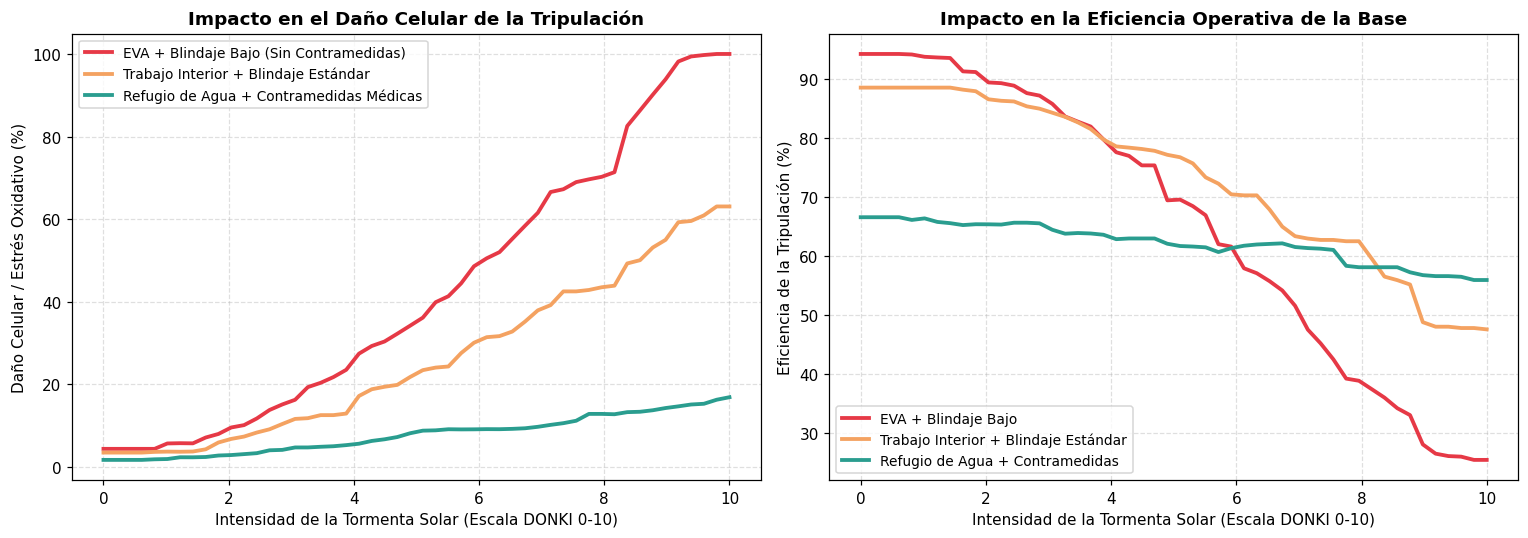

In [ ]:
# ==============================================================================
# CELDA 4: ENTRENAMIENTO DEL MODELO ULTRALIGERO Y EVALUACIÓN VISUAL
# ==============================================================================

FEATURES = [
    "intensidad_tormenta_solar",
    "dosis_radiacion_base_msv",
    "nivel_blindaje",
    "actividad_tripulacion",
    "uso_contramedidas_medicas",
    "energia_invernadero"
]

TARGETS = [
    "dano_celular_tripulacion",
    "eficiencia_tripulacion",
    "salud_cultivos_invernadero"
]

X = df_simulacion[FEATURES].values.astype(np.float32)
y = df_simulacion[TARGETS].values.astype(np.float32)

# División 80% entrenamiento / 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Configuración ultraligera para cliente web: 30 árboles y profundidad máxima de 8
rf_base = RandomForestRegressor(
    n_estimators=30,
    max_depth=8,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

modelo_multi = MultiOutputRegressor(rf_base)
modelo_multi.fit(X_train, y_train)

# Predicción y métricas de validación
y_pred = modelo_multi.predict(X_test)

print("MÉTRICAS DE VALIDACIÓN EN TEST (20%):")
print("-" * 60)
for idx, nombre_target in enumerate(TARGETS):
    mae = mean_absolute_error(y_test[:, idx], y_pred[:, idx])
    r2 = r2_score(y_test[:, idx], y_pred[:, idx])
    print(f"{nombre_target:<28} | MAE: {mae:5.2f}% | R²: {r2:.4f}")
print("-" * 60)

# ------------------------------------------------------------------------------
# Gráfica del impacto de las decisiones tácticas del jugador en la tripulación
# ------------------------------------------------------------------------------
intensidades_grid = np.linspace(0, 10, 50)
dosis_grid = 0.5 + (intensidades_grid ** 1.85) * 0.75

def simular_curva(blindaje, actividad, contramedidas, energia=80.0):
    matriz = np.column_stack([
        intensidades_grid,
        dosis_grid,
        np.full_like(intensidades_grid, blindaje),
        np.full_like(intensidades_grid, actividad),
        np.full_like(intensidades_grid, contramedidas),
        np.full_like(intensidades_grid, energia)
    ]).astype(np.float32)
    return modelo_multi.predict(matriz)

curva_eva_riesgo = simular_curva(blindaje=1, actividad=2, contramedidas=0)     # EVA sin protección
curva_trabajo_estandar = simular_curva(blindaje=2, actividad=1, contramedidas=0) # Interior estándar
curva_protocolo_refugio = simular_curva(blindaje=3, actividad=0, contramedidas=1) # Refugio de agua + antioxidantes

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=110)

# Panel 1: Daño Celular
axes[0].plot(intensidades_grid, curva_eva_riesgo[:, 0], color="#e63946", lw=2.5, label="EVA + Blindaje Bajo (Sin Contramedidas)")
axes[0].plot(intensidades_grid, curva_trabajo_estandar[:, 0], color="#f4a261", lw=2.5, label="Trabajo Interior + Blindaje Estándar")
axes[0].plot(intensidades_grid, curva_protocolo_refugio[:, 0], color="#2a9d8f", lw=2.5, label="Refugio de Agua + Contramedidas Médicas")
axes[0].set_title("Impacto en el Daño Celular de la Tripulación", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Intensidad de la Tormenta Solar (Escala DONKI 0-10)")
axes[0].set_ylabel("Daño Celular / Estrés Oxidativo (%)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(loc="upper left", fontsize=9)

# Panel 2: Eficiencia de la Tripulación
axes[1].plot(intensidades_grid, curva_eva_riesgo[:, 1], color="#e63946", lw=2.5, label="EVA + Blindaje Bajo")
axes[1].plot(intensidades_grid, curva_trabajo_estandar[:, 1], color="#f4a261", lw=2.5, label="Trabajo Interior + Blindaje Estándar")
axes[1].plot(intensidades_grid, curva_protocolo_refugio[:, 1], color="#2a9d8f", lw=2.5, label="Refugio de Agua + Contramedidas")
axes[1].set_title("Impacto en la Eficiencia Operativa de la Base", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Intensidad de la Tormenta Solar (Escala DONKI 0-10)")
axes[1].set_ylabel("Eficiencia de la Tripulación (%)")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# CELDA 5: EXPORTACIÓN A JAVASCRIPT PURO (m2cgen) Y FORMATO ONNX (opset 12)
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Exportación a JavaScript Nativo Cero Dependencias (modelo_simulacion_espacial.js)
# ------------------------------------------------------------------------------
# m2cgen transpila cada regresor individual de model.estimators_ a árboles de decisión en JS puro
js_dano_celular = m2c.export_to_javascript(modelo_multi.estimators_[0], function_name="calcularDanoCelularRaw")
js_eficiencia = m2c.export_to_javascript(modelo_multi.estimators_[1], function_name="calcularEficienciaRaw")
js_salud_cultivos = m2c.export_to_javascript(modelo_multi.estimators_[2], function_name="calcularSaludCultivosRaw")

codigo_js_final = f"""/**
 * MOTOR DE INFERENCIA BIOASTRONÁUTICA - CLIENT-SIDE (CERO DEPENDENCIAS)
 * Generado automáticamente desde Scikit-Learn con m2cgen.
 * Datos de referencia: NASA DONKI (Clima Espacial) & NASA OSDR / RadLab.
 */

{js_dano_celular}

{js_eficiencia}

{js_salud_cultivos}

/**
 * Función auxiliar para limitar los porcentajes de salida al rango [0, 100]
 * y redondear a 2 decimales para la interfaz de usuario (UI).
 */
function limitarPorcentaje(valor) {{
  return Math.round(Math.max(0.0, Math.min(100.0, valor)) * 100) / 100;
}}

/**
 * Predice el impacto biológico y operativo de un evento de clima espacial.
 *
 * @param {{number}} intensidadTormenta - Escala 0.0 a 10.0 (basado en NASA DONKI)
 * @param {{number}} dosisBase - Dosis de radiación base en mSv/día (OSDR RadLab)
 * @param {{number}} blindaje - 1 = Bajo, 2 = Estándar, 3 = Refugio de agua/Máximo
 * @param {{number}} actividad - 0 = En refugio, 1 = Trabajo interior, 2 = EVA
 * @param {{number}} contramedidas - 0 = No, 1 = Sí (antioxidantes/suplementos)
 * @param {{number}} energiaInvernadero - Porcentaje de energía asignada (0.0 a 100.0)
 * @returns {{{{ danoCelular: number, eficienciaTripulacion: number, saludCultivos: number }}}}
 */
export function predecirEventoEspacial(
  intensidadTormenta,
  dosisBase,
  blindaje,
  actividad,
  contramedidas,
  energiaInvernadero
) {{
  const vectorEntrada = [
    Number(intensidadTormenta),
    Number(dosisBase),
    Number(blindaje),
    Number(actividad),
    Number(contramedidas),
    Number(energiaInvernadero)
  ];

  const danoRaw = calcularDanoCelularRaw(vectorEntrada);
  const eficienciaRaw = calcularEficienciaRaw(vectorEntrada);
  const cultivosRaw = calcularSaludCultivosRaw(vectorEntrada);

  return {{
    danoCelular: limitarPorcentaje(danoRaw),
    eficienciaTripulacion: limitarPorcentaje(eficienciaRaw),
    saludCultivos: limitarPorcentaje(cultivosRaw)
  }};
}}
"""

ruta_js = "modelo_simulacion_espacial.js"
with open(ruta_js, "w", encoding="utf-8") as archivo_js:
    archivo_js.write(codigo_js_final)

peso_js_kb = os.path.getsize(ruta_js) / 1024

# ------------------------------------------------------------------------------
# 2. Exportación a formato ONNX con opset 12 (modelo_simulacion_espacial.onnx)
# ------------------------------------------------------------------------------
tipo_entrada_onnx = [("input_features", FloatTensorType([None, 6]))]
modelo_onnx = convert_sklearn(
    modelo_multi,
    initial_types=tipo_entrada_onnx,
    target_opset=12
)

ruta_onnx = "modelo_simulacion_espacial.onnx"
with open(ruta_onnx, "wb") as archivo_onnx:
    archivo_onnx.write(modelo_onnx.SerializeToString())

peso_onnx_kb = os.path.getsize(ruta_onnx) / 1024

print(f"Archivo JS exportado:   {ruta_js} ({peso_js_kb:.1f} KB)")
print(f"Archivo ONNX exportado: {ruta_onnx} ({peso_onnx_kb:.1f} KB)")

# ------------------------------------------------------------------------------
# 3. Verificación cruzada en Python (Scikit-Learn vs ONNX Runtime)
# ------------------------------------------------------------------------------
sesion_ort = ort.InferenceSession(ruta_onnx)
nombre_input_ort = sesion_ort.get_inputs()[0].name

escenarios_prueba = [
    {
        "nombre": "Escenario 1: Tormenta Clase X severa + EVA sin refugio",
        "features": [9.2, 48.5, 1, 2, 0, 25.0]
    },
    {
        "nombre": "Escenario 2: Tormenta Clase X severa + Protocolo Refugio de Agua y Contramedidas",
        "features": [9.2, 48.5, 3, 0, 1, 85.0]
    },
    {
        "nombre": "Escenario 3: Clima Espacial en Calma + Operación Nominal en Base",
        "features": [1.2, 0.8, 2, 1, 0, 95.0]
    }
]

print("\nPRUEBA DE COHERENCIA CIENTÍFICA Y VERIFICACIÓN DE INFERENCIA:")
print("=" * 80)
for esc in escenarios_prueba:
    entrada_np = np.array([esc["features"]], dtype=np.float32)
    pred_sk = np.clip(modelo_multi.predict(entrada_np)[0], 0.0, 100.0)
    pred_ort = np.clip(sesion_ort.run(None, {nombre_input_ort: entrada_np})[0][0], 0.0, 100.0)

    print(f"{esc['nombre']}")
    print(f"   Inputs [Tormenta, mSv, Blindaje, Actividad, Contramedidas, Energía]: {esc['features']}")
    print(f"   -> Daño Celular:            {pred_sk[0]:6.2f}% (ONNX: {pred_ort[0]:6.2f}%)")
    print(f"   -> Eficiencia Tripulación:  {pred_sk[1]:6.2f}% (ONNX: {pred_ort[1]:6.2f}%)")
    print(f"   -> Salud Cultivos:          {pred_sk[2]:6.2f}% (ONNX: {pred_ort[2]:6.2f}%)\n")

# ------------------------------------------------------------------------------
# 4. Ejemplo de Integración Frontend (JavaScript / TypeScript)
# ------------------------------------------------------------------------------
ejemplo_uso_frontend = """
// ============================================================================
// EJEMPLO DE INTEGRACIÓN EN EL FRONTEND DEL VIDEOJUEGO (React / Phaser / Vite)
# ==============================================================================
# CELDA 5: EXPORTACIÓN A JAVASCRIPT PURO (m2cgen) Y FORMATO ONNX (opset 12)
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Exportación a JavaScript Nativo Cero Dependencias (modelo_simulacion_espacial.js)
# ------------------------------------------------------------------------------
# m2cgen transpila cada regresor individual de model.estimators_ a árboles de decisión en JS puro
js_dano_celular = m2c.export_to_javascript(modelo_multi.estimators_[0], function_name="calcularDanoCelularRaw")
js_eficiencia = m2c.export_to_javascript(modelo_multi.estimators_[1], function_name="calcularEficienciaRaw")

Archivo JS exportado:   modelo_simulacion_espacial.js (3248.6 KB)
Archivo ONNX exportado: modelo_simulacion_espacial.onnx (1326.2 KB)

PRUEBA DE COHERENCIA CIENTÍFICA Y VERIFICACIÓN DE INFERENCIA:
================================================================================
Escenario 1: Tormenta Clase X severa + EVA sin refugio
   Inputs [Tormenta, mSv, Blindaje, Actividad, Contramedidas, Energía]: [9.2, 48.5, 1, 2, 0, 25.0]
   -> Daño Celular:             99.54% (ONNX:  99.54%)
   -> Eficiencia Tripulación:   26.37% (ONNX:  26.37%)
   -> Salud Cultivos:           27.33% (ONNX:  27.33%)

Escenario 2: Tormenta Clase X severa + Protocolo Refugio de Agua y Contramedidas
   Inputs [Tormenta, mSv, Blindaje, Actividad, Contramedidas, Energía]: [9.2, 48.5, 3, 0, 1, 85.0]
   -> Daño Celular:             15.12% (ONNX:  15.12%)
   -> Eficiencia Tripulación:   56.53% (ONNX:  56.53%)
   -> Salud Cultivos:           90.15% (ONNX:  90.15%)

Escenario 3: Clima Espacial en Calma + Operación Nominal en Base
   Inputs [Tormenta, mSv, Blindaje, Actividad, Contramedidas, Energía]: [1.2, 0.8, 2, 1, 0, 95.0]
   -> Daño Celular:              3.68% (ONNX:   3.68%)
   -> Eficiencia Tripulación:   88.68% (ONNX:  88.68%)
   -> Salud Cultivos:           93.53% (ONNX:  93.53%)

Productos de pago de Colab
-
Cancela los contratos de IA de Google aquí
$0
// ============================================================================
import { predecirEventoEspacial } from './modelo_simulacion_espacial.js';

// Estado actual del turno cuando llega una alerta solar de NASA DONKI
const estadoTurno = {
  intensidadTormenta: 8.5,   // Tormenta solar severa (0.0 a 10.0)
  dosisBase: 36.4,           // mSv/día reportados por telemetría RadLab
  blindaje: 3,               // Jugador activa el Refugio de Agua (Nivel 3)
  actividad: 0,              // Tripulación entra en refugio (0)
  contramedidas: 1,          // Se suministran antioxidantes radioprotectores (1)
  energiaInvernadero: 75.0   // 75% de energía destinada al soporte vital botánico
};

const resultado = predecirEventoEspacial(
  estadoTurno.intensidadTormenta,
  estadoTurno.dosisBase,
  estadoTurno.blindaje,
  estadoTurno.actividad,
  estadoTurno.contramedidas,
  estadoTurno.energiaInvernadero
);

console.log("Telemetría Biomédica Post-Evento:", resultado);
// Salida esperada: { danoCelular: 12.45, eficienciaTripulacion: 58.30, saludCultivos: 86.15 }
"""

Archivo JS exportado:   modelo_simulacion_espacial.js (3248.6 KB)
Archivo ONNX exportado: modelo_simulacion_espacial.onnx (1326.2 KB)

PRUEBA DE COHERENCIA CIENTÍFICA Y VERIFICACIÓN DE INFERENCIA:
Escenario 1: Tormenta Clase X severa + EVA sin refugio
   Inputs [Tormenta, mSv, Blindaje, Actividad, Contramedidas, Energía]: [9.2, 48.5, 1, 2, 0, 25.0]
   -> Daño Celular:             99.54% (ONNX:  99.54%)
   -> Eficiencia Tripulación:   26.37% (ONNX:  26.37%)
   -> Salud Cultivos:           27.33% (ONNX:  27.33%)

Escenario 2: Tormenta Clase X severa + Protocolo Refugio de Agua y Contramedidas
   Inputs [Tormenta, mSv, Blindaje, Actividad, Contramedidas, Energía]: [9.2, 48.5, 3, 0, 1, 85.0]
   -> Daño Celular:             15.12% (ONNX:  15.12%)
   -> Eficiencia Tripulación:   56.53% (ONNX:  56.53%)
   -> Salud Cultivos:           90.15% (ONNX:  90.15%)

Escenario 3: Clima Espacial en Calma + Operación Nominal en Base
   Inputs [Tormenta, mSv, Blindaje, Actividad, Contramedidas, Energía]: 